# GDP development across seven countries, 2000–2022
Annual GDP, current US dollars. Source: World Bank (NY.GDP.MKTP.CD).


In [3]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.load_data import load_gdp
from src.clean_data import clean_gdp
from src.plot_data import plot_gdp, plot_indexed_gdp


## Load and clean
The implementation is in reusable modules, not in this notebook.


In [4]:
raw = load_gdp()
gdp = clean_gdp(raw)
(ROOT / "data").mkdir(exist_ok=True)
raw.to_csv(ROOT / "data" / "gdp_raw.csv", index=False)
gdp.to_csv(ROOT / "data" / "gdp_clean.csv", index=False)
print(gdp.groupby("country")["year"].agg(["min", "max", "count"]))
display(gdp.head())


                 min   max  count
country                          
Brazil          2000  2022     23
China           2000  2022     23
Germany         2000  2022     23
Japan           2000  2022     23
Switzerland     2000  2022     23
United Kingdom  2000  2022     23
United States   2000  2022     23


,country,year,gdp_usd,gdp_trillion_usd
0,Brazil,2000,6.554482e+11,0.655448
1,Brazil,2001,5.599836e+11,0.559984
2,Brazil,2002,5.097953e+11,0.509795
3,Brazil,2003,5.582337e+11,0.558234
4,Brazil,2004,6.692894e+11,0.669289


## Visualise


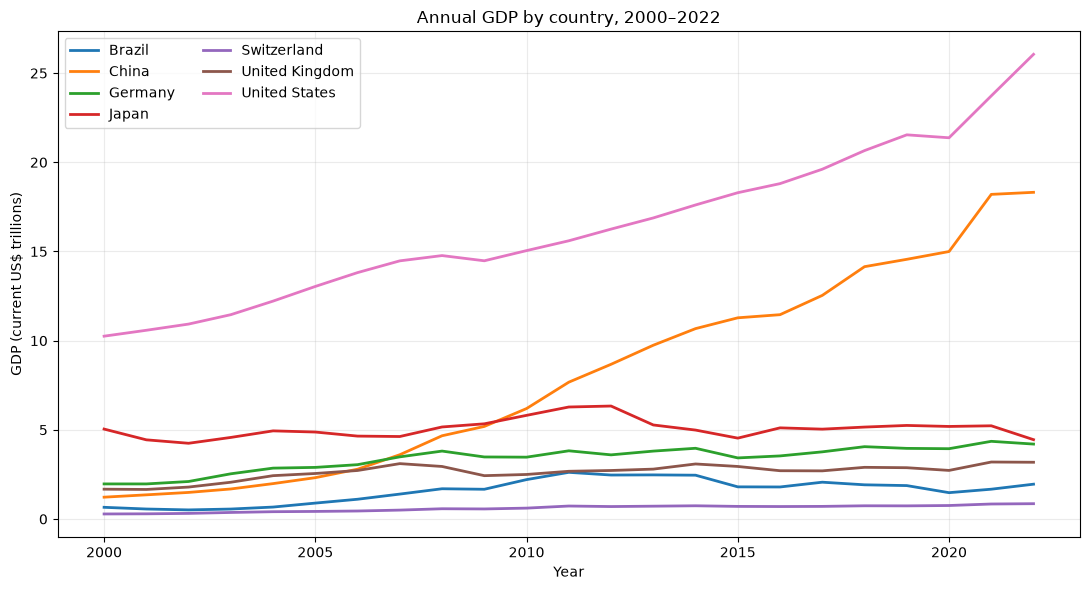

In [5]:
(ROOT / "figures").mkdir(exist_ok=True)
fig, ax = plot_gdp(gdp, ROOT / "figures" / "gdp_levels.png")


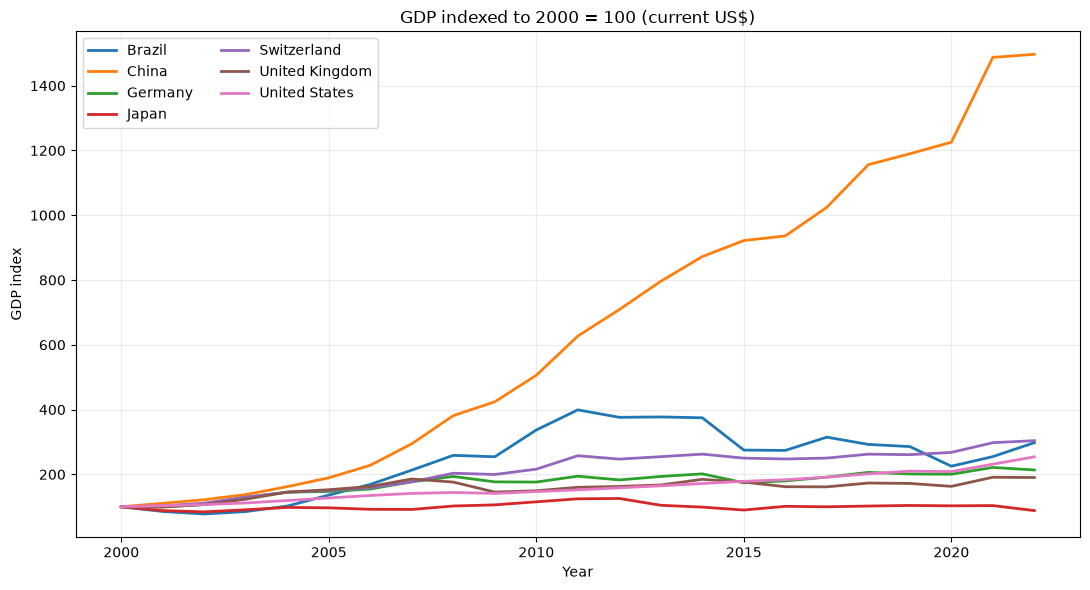

In [6]:
fig, ax = plot_indexed_gdp(gdp, ROOT / "figures" / "gdp_indexed.png")


## Quantitative summary


In [7]:
wide = gdp.pivot(index="country", columns="year", values="gdp_usd")
summary = wide[[2000, 2022]].copy() / 1e12
summary.columns = ["GDP 2000 ($tn)", "GDP 2022 ($tn)"]
summary["Nominal USD change (%)"] = (wide[2022] / wide[2000] - 1) * 100
display(summary.round(2))


,GDP 2000 ($tn),GDP 2022 ($tn),Nominal USD change (%)
country,,,
Brazil,0.66,1.95,197.80
China,1.22,18.32,1396.77
Germany,1.97,4.20,113.58
Japan,5.04,4.45,-11.79
Switzerland,0.28,0.86,204.07
United Kingdom,1.67,3.18,90.31
United States,10.25,26.05,154.17


## Brief interpretation

- **China:** Very rapid expansion in US-dollar GDP, narrowing the gap with the United States.
- **United States:** Remained the largest economy by nominal US-dollar GDP throughout this period.
- **United Kingdom, Germany, Japan and Switzerland:** Generally higher dollar GDP by 2022 than in 2000, but with fluctuations; exchange-rate movements substantially affect comparisons.
- **Brazil:** Strong growth in parts of the 2000s, followed by significant volatility and periods of decline in dollar terms.
- **Common shocks:** The 2008–09 global financial crisis and 2020 pandemic affected GDP trajectories, although magnitudes differ by country.

**Caution:** These are observations about GDP measured in *current US dollars*, not inflation-adjusted output growth. For causal explanations or real-growth comparisons, additional data and analysis are necessary.
